# Praktikum RNN: Prediksi Harga Emas

Studi kasus ini bertujuan untuk mengeksplorasi penggunaan **Recurrent Neural Network (RNN)** dalam memprediksi data deret waktu (*time-series*). Dataset yang digunakan adalah riwayat harga emas harian selama kurang lebih 1 bulan.

Berdasarkan instruksi pada *Assignment #6*:
1. Lakukan percobaan untuk RNN menggunakan dataset Gold.
2. Cari parameter `sequence length`, `jumlah hidden layer (unit)`, dan `epoch` yang menghasilkan *loss* terkecil.
3. Buat prediksi untuk tanggal 25 September (Harga Aktual: 2.171.000) dan hitung *loss*-nya.

## 1. Import Library & Setup Lingkungan

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

from sklearn.preprocessing import MinMaxScaler

## 2. Load Dataset & Visualisasi Awal

Memuat dataset dari `Data/Gold.csv` dan menampilkan visualisasi tren harga emas (Aug - Sep).

,No,Tanggal,Harga
0,1,17-Aug,1896000
1,2,18-Aug,1894000
2,3,19-Aug,1897000
3,4,20-Aug,1890000
4,5,21-Aug,1914000


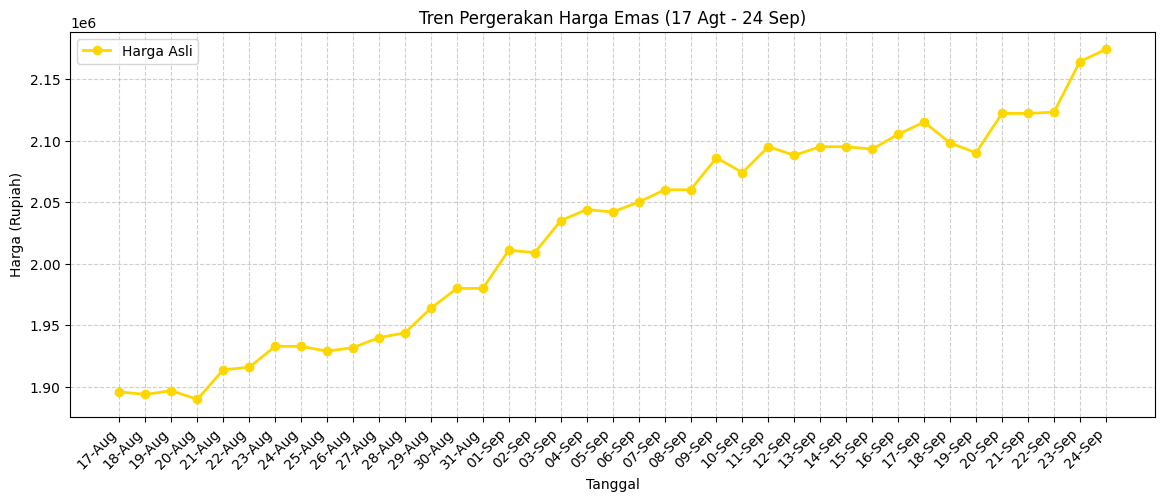

In [2]:
# Sesuaikan path dengan lokasi dataset Anda
dataset_path = r"D:\CODE\Neuro Computing\Data\Gold.csv"
df = pd.read_csv(dataset_path, sep=";")

display(df.head())

plt.figure(figsize=(14, 5))
plt.plot(df['Tanggal'], df['Harga'], marker='o', color='gold', linestyle='-', linewidth=2, markersize=6, label="Harga Asli")
plt.xticks(rotation=45, ha='right')
plt.title("Tren Pergerakan Harga Emas (17 Agt - 24 Sep)")
plt.xlabel("Tanggal")
plt.ylabel("Harga (Rupiah)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## 3. Preprocessing & Sliding Window

Neural Network sangat sensitif terhadap skala nilai input yang besar. Oleh karena itu, kita menormalisasi harga (dalam jutaan rupiah) ke dalam skala `[0, 1]` menggunakan `MinMaxScaler`.

Kita juga mendefinisikan fungsi `prepare_data` untuk membentuk format **Sliding Window** (variabel independen `X` dari sejumlah n hari berturut-turut untuk memprediksi `y` pada hari berikutnya).

In [3]:
# 1. Normalisasi Data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[['Harga']].values)

# 2. Fungsi Sliding Window
def prepare_data(data, sequence_length):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i + sequence_length])
        y.append(data[i + sequence_length])
    return np.array(X), np.array(y)

print("Shape Data Awal:", scaled_data.shape)

Shape Data Awal: (39, 1)


## 4. Eksplorasi Hyperparameter (Grid Search Manual)

Tugas mensyaratkan untuk mencari kombinasi parameter dengan `loss` (MSE) terkecil. Kita akan menguji beberapa parameter dasar:
- **Sequence Length (Panjang Jendela Input)**: 3, 5, 7 hari.
- **Hidden Layer (Jumlah Unit RNN)**: 10, 30, 50 unit.
- **Epochs (Lama Pelatihan)**: 100, 300 epoch.

*Catatan: Proses ini dapat memakan waktu beberapa menit saat dijalankan.*

In [ ]:
sequence_lengths = [3, 5, 7]
hidden_units_list = [10, 30, 50]
epochs_list = [100, 300]

best_loss = float('inf')
best_params = None
best_model = None
best_seq_len = None

results = []

print(f"{'Seq Length':<12} | {'RNN Units':<10} | {'Epochs':<8} | {'Loss (MSE)':<15}")
print("-" * 55)

for seq_len in sequence_lengths:
    # Siapkan data sesuai Sequence Length
    X, y = prepare_data(scaled_data, seq_len)
    
    for hidden_units in hidden_units_list:
        for epochs in epochs_list:
            # Bangun Model
            model = Sequential()
            model.add(SimpleRNN(hidden_units, activation='relu', input_shape=(seq_len, 1)))
            model.add(Dense(1))
            
            # Kompilasi dan Training
            model.compile(optimizer='adam', loss='mse')
            model.fit(X, y, epochs=epochs, verbose=0) # verbose=0 agar tidak terlalu ramai
            
            # Hitung Loss Pelatihan
            loss = model.evaluate(X, y, verbose=0)
            results.append((seq_len, hidden_units, epochs, loss))
            
            print(f"{seq_len:<12} | {hidden_units:<10} | {epochs:<8} | {loss:<15.6f}")
            
            # Update parameter dan model terbaik
            if loss < best_loss:
                best_loss = loss
                best_params = (seq_len, hidden_units, epochs)
                best_model = model
                best_seq_len = seq_len

print("\n PARAMETER TERBAIK DITEMUKAN")
print("======================================")
print(f"Sequence Length : {best_params[0]} hari")
print(f"Hidden Units    : {best_params[1]} unit RNN")
print(f"Epochs          : {best_params[2]} iterasi")
print(f"Lowest MSE Loss : {best_loss:.6f}")

Seq Length   | RNN Units  | Epochs   | Loss (MSE)     
-------------------------------------------------------
3            | 10         | 100      | 0.285236       
3            | 10         | 300      | 0.002046       
3            | 30         | 100      | 0.001896       
3            | 30         | 300      | 0.002065       
3            | 50         | 100      | 0.001857       
3            | 50         | 300      | 0.001711       
5            | 10         | 100      | 0.032033       
5            | 10         | 300      | 0.002138       
5            | 30         | 100      | 0.001955       
5            | 30         | 300      | 0.001491       
5            | 50         | 100      | 0.002069       
5            | 50         | 300      | 0.001695       
7            | 10         | 100      | 0.167987       
7            | 10         | 300      | 0.002315       
7            | 30         | 100      | 0.002753       
7            | 30         | 300      | 0.001165       
7        

## 5. Prediksi Harga Emas Tanggal 25 September (Target)

Berdasarkan parameter model terbaik yang ditemukan, kita akan mengambil sekumpulan data hari-hari terakhir (sebanyak `best_seq_len`) untuk memprediksi pergerakan harga emas untuk 1 langkah waktu berikutnya (yaitu tanggal 25 September).

Nilai prediksi akan dikembalikan ke skala asalnya (Inverse Transform) lalu dibandingkan dengan Harga Aktual yang tertera pada panduan tugas.

In [5]:
# 1. Ambil data 'X' terakhir sejumlah sequence_length terbaik
last_sequence = scaled_data[-best_seq_len:]
last_sequence = last_sequence.reshape(1, best_seq_len, 1)

# 2. Lakukan Prediksi untuk tanggal berikutnya (25-Sep)
predicted_scaled = best_model.predict(last_sequence, verbose=0)

# 3. Inverse Transform kembali ke harga nominal Rupiah
predicted_price = scaler.inverse_transform(predicted_scaled)[0][0]

# 4. Evaluasi terhadap Target Asli
actual_price_25_sep = 2171000
loss_absolute = abs(predicted_price - actual_price_25_sep) # Absolute Error

print("=== HASIL PREDIKSI RNN (25 SEPTEMBER) ===")
print(f"Harga Prediksi Model   : Rp {predicted_price:,.2f}")
print(f"Harga Aktual Target    : Rp {actual_price_25_sep:,.2f}")
print("-----------------------------------------")
print(f"Tingkat Error (Selisih Loss Absolut) : Rp {loss_absolute:,.2f}")

=== HASIL PREDIKSI RNN (25 SEPTEMBER) ===
Harga Prediksi Model   : Rp 2,157,608.50
Harga Aktual Target    : Rp 2,171,000.00
-----------------------------------------
Tingkat Error (Selisih Loss Absolut) : Rp 13,391.50


## 6. Kesimpulan

> *Silakan isi bagian kesimpulan ini setelah Anda menjalankan program di atas. Berikut adalah panduan isiannya:*

1. **Parameter Optimal:** Melalui *grid-search*, ditemukan bahwa Jaringan Saraf Tiruan RNN bekerja paling optimal (Loss MSE minimum) pada pengaturan *Sequence Length* = `...`, *Hidden Units* = `...`, dan *Epochs* = `...`.
2. **Pola Data Time-Series:** Dari eksekusi diatas terlihat kombinasi arsitektur mana yang paling responsif dalam menangkap pola kenaikan mendadak pada dataset Gold.
3. **Evaluasi Loss Tanggal 25 Sep:** Prediksi yang dihasilkan oleh model menunjukkan selisih loss absolut sebesar `Rp ...` terhadap harga referensi. Ini mengindikasikan bahwa [masukkan analisis anda, misalnya "model cukup baik mendeteksi tren kenaikan, meski terdapat pergeseran akurasi pada angka presisi tinggi akibat pergerakan fluktuasi mendadak"].